In [11]:
%pip install tensorflow numpy matplotlib seaborn scikit-learn streamlit pillow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
import json
import os
import time
import matplotlib.pyplot as plt
import numpy as np
import seaborn as tf_sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau,
)
from tensorflow.keras.optimizers import Adam

In [13]:
BASE_DIR = r'D:\Klasifikasi Citra Emosi Wajah Menggunakan CNN'
DATA_DIR = os.path.join(BASE_DIR, 'processed_data')
TRAIN_DIR = os.path.join(DATA_DIR, 'train')
TEST_DIR = os.path.join(DATA_DIR, 'test')

IMG_SIZE = (
    48,
    48,
)  # Ukuran standar FER2013 (bisa dinaikkan jika pakai MobileNetV2 ke 96x96/160x160)
BATCH = 64
EPOCHS = 10
FINE_TUNE_EPOCHS = 3
SEED = 42
OUT_DIR = os.path.join(BASE_DIR, 'output')
os.makedirs(OUT_DIR, exist_ok=True)

tf.keras.utils.set_random_seed(SEED)
print(f'Dataset Train Path: {TRAIN_DIR}')

Dataset Train Path: D:\Klasifikasi Citra Emosi Wajah Menggunakan CNN\processed_data\train


In [17]:
common = dict(
    validation_split=0.2,
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH,
    label_mode='categorical',
    color_mode='grayscale',
)

train_raw = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, subset='training', **common
)
val_raw = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, subset='validation', **common
)

class_names = train_raw.class_names
NUM_CLASSES = len(class_names)
print(f'Kelas ({NUM_CLASSES}): {class_names}')

# Simpan nama kelas ke JSON untuk Streamlit
with open(os.path.join(OUT_DIR, 'class_names.json'), 'w') as f:
  json.dump(class_names, f)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_raw.cache().shuffle(1000, seed=SEED).prefetch(AUTOTUNE)
val_ds = val_raw.cache().prefetch(AUTOTUNE)

Found 49779 files belonging to 7 classes.
Using 39824 files for training.
Found 49779 files belonging to 7 classes.
Using 9955 files for validation.
Kelas (7): ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


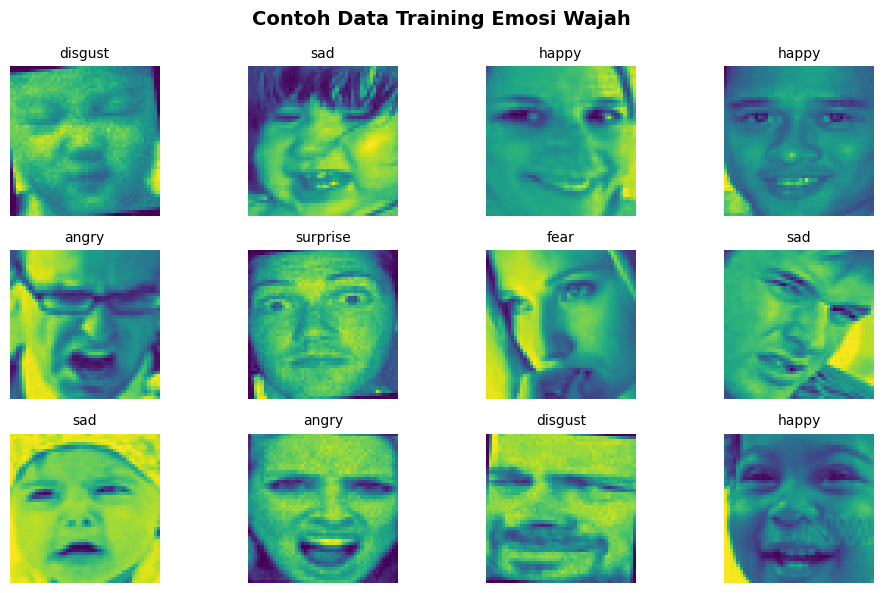

In [18]:
plt.figure(figsize=(10, 6))
for images, labels in train_raw.take(1):
  for i in range(min(12, len(images))):
    plt.subplot(3, 4, i + 1)
    plt.imshow(images[i].numpy().astype('uint8'))
    plt.title(class_names[int(np.argmax(labels[i]))], fontsize=10)
    plt.axis('off')
plt.suptitle('Contoh Data Training Emosi Wajah', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, '1_sample_data.png'), dpi=120)
plt.show()

In [19]:
augment = models.Sequential(
    [
        layers.RandomFlip('horizontal'),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
    ],
    name='augmentation',
)

# Membangun Arsitektur Custom CNN yang optimal untuk gambar 48x48
inputs = layers.Input(shape=IMG_SIZE + (1,))
x = augment(inputs)
x = layers.Rescaling(1.0 / 255.0)(x)

x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Flatten()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

model = models.Model(inputs, outputs, name='emotion_cnn')

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy'],
)
model.summary()

Model: "emotion_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,274,375 (4.86 MB)

 Trainable params: 1,274,375 (4.86 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
ckpt_path = os.path.join(OUT_DIR, 'emotion_cnn_best.keras')
callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=4, restore_best_weights=True),
    ModelCheckpoint(ckpt_path, monitor='val_accuracy', save_best_only=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-6),
]

t0 = time.time()
print('\nMulai training model CNN...')
history = model.fit(
    train_ds, epochs=EPOCHS, validation_data=val_ds, callbacks=callbacks
)
print(f'Total waktu training: {(time.time() - t0) / 60:.1f} menit')


Mulai training model CNN...
Epoch 1/10


C:\Users\user\AppData\Roaming\Python\Python313\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


623/623 ━━━━━━━━━━━━━━━━━━━━ 160s 125ms/step - accuracy: 0.3023 - loss: 1.7785 - val_accuracy: 0.4268 - val_loss: 1.5276 - learning_rate: 0.0010
Epoch 2/10
623/623 ━━━━━━━━━━━━━━━━━━━━ 57s 91ms/step - accuracy: 0.4058 - loss: 1.5597 - val_accuracy: 0.4926 - val_loss: 1.3472 - learning_rate: 0.0010
Epoch 3/10
623/623 ━━━━━━━━━━━━━━━━━━━━ 64s 102ms/step - accuracy: 0.4546 - loss: 1.4465 - val_accuracy: 0.5241 - val_loss: 1.2592 - learning_rate: 0.0010
Epoch 4/10
623/623 ━━━━━━━━━━━━━━━━━━━━ 57s 92ms/step - accuracy: 0.4804 - loss: 1.3802 - val_accuracy: 0.5412 - val_loss: 1.2286 - learning_rate: 0.0010
Epoch 5/10
623/623 ━━━━━━━━━━━━━━━━━━━━ 57s 92ms/step - accuracy: 0.5006 - loss: 1.3292 - val_accuracy: 0.5564 - val_loss: 1.1748 - learning_rate: 0.0010
Epoch 6/10
623/623 ━━━━━━━━━━━━━━━━━━━━ 60s 96ms/step - accuracy: 0.5089 - loss: 1.2949 - val_accuracy: 0.5646 - val_loss: 1.1490 - learning_rate: 0.0010
Epoch 7/10
623/623 ━━━━━━━━━━━━━━━━━━━━ 57s 92ms/step - accuracy: 0.5238 - loss: 1.2


Akurasi Validasi Akhir: 59.20%
Loss Validasi: 1.0915


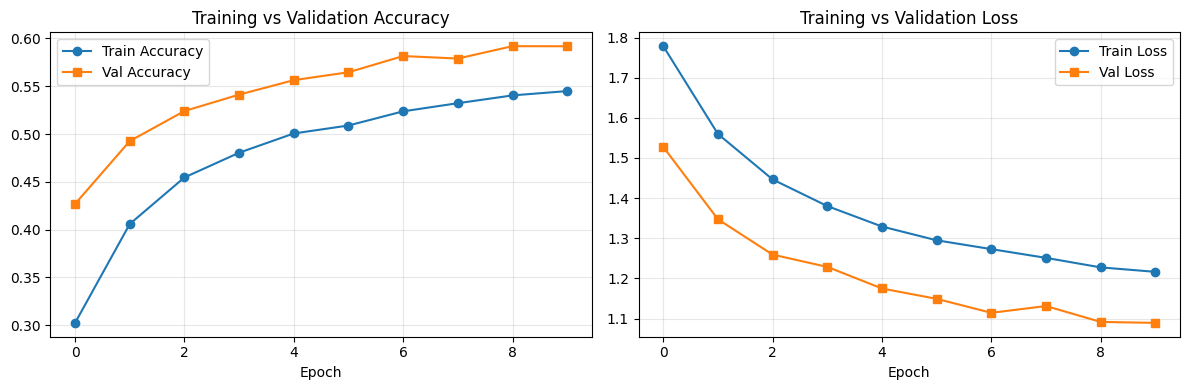


CLASSIFICATION REPORT

              precision    recall  f1-score   support

       angry      0.476     0.396     0.433      1211
     disgust      0.576     0.798     0.669      1196
        fear      0.400     0.323     0.357      1177
       happy      0.802     0.839     0.820      2342
     neutral      0.536     0.546     0.541      1583
         sad      0.435     0.363     0.396      1274
    surprise      0.646     0.673     0.659      1172

    accuracy                          0.592      9955
   macro avg      0.553     0.562     0.554      9955
weighted avg      0.580     0.592     0.582      9955



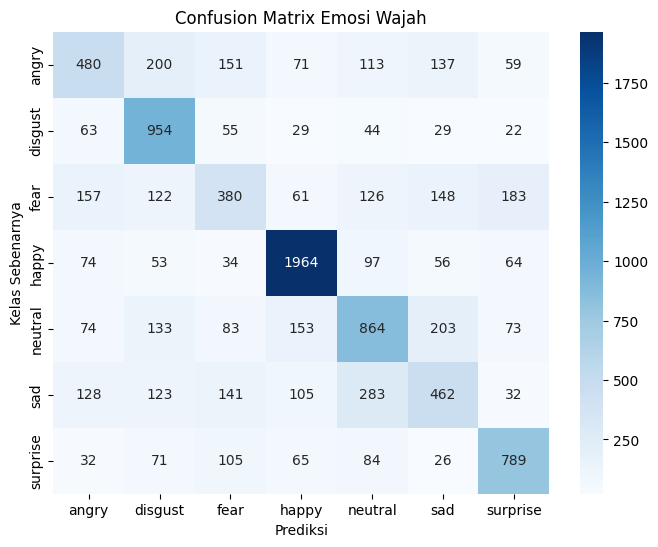

In [21]:
# 1. Evaluasi akhir
loss, acc = model.evaluate(val_ds, verbose=0)
print(f'\nAkurasi Validasi Akhir: {acc * 100:.2f}%')
print(f'Loss Validasi: {loss:.4f}')

# 2. Grafik Akurasi & Loss
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (metric, title) in zip(
    ax, [('accuracy', 'Accuracy'), ('loss', 'Loss')]
):
  a.plot(history.history[metric], 'o-', label=f'Train {title}')
  a.plot(history.history[f'val_{metric}'], 's-', label=f'Val {title}')
  a.set_title(f'Training vs Validation {title}')
  a.set_xlabel('Epoch')
  a.legend()
  a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, '2_training_curves.png'), dpi=120)
plt.show()

# 3. Prediksi & Confusion Matrix
y_true, y_pred = [], []
for xb, yb in val_ds:
  p = model.predict(xb, verbose=0)
  true_batch = np.argmax(yb.numpy(), axis=1)
  pred_batch = np.argmax(p, axis=1)
  y_true.extend(true_batch)
  y_pred.extend(pred_batch)

y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)

print('\nCLASSIFICATION REPORT\n')
print(
    classification_report(
        y_true, y_pred, target_names=class_names, digits=3, zero_division=0
    )
)

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(8, 6))
tf_sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    ax=ax,
)
ax.set_xlabel('Prediksi')
ax.set_ylabel('Kelas Sebenarnya')
ax.set_title('Confusion Matrix Emosi Wajah')
plt.savefig(os.path.join(OUT_DIR, '3_confusion_matrix.png'), dpi=120)
plt.show()

In [22]:
model.save(os.path.join(OUT_DIR, 'final_emotion_cnn_model.keras'))
print(
    f'\n Model berhasil disimpan di folder: {os.path.abspath(OUT_DIR)}'
)


 Model berhasil disimpan di folder: D:\Klasifikasi Citra Emosi Wajah Menggunakan CNN\output


In [16]:
import os

# Definisikan ulang path train_dir
TRAIN_DIR = r'D:\Klasifikasi Citra Emosi Wajah Menggunakan CNN\processed_data\train'

print('Path yang dicek:', TRAIN_DIR)
print('Apakah folder train ditemukan?', os.path.exists(TRAIN_DIR))

if os.path.exists(TRAIN_DIR):
  print('Isi folder train (Daftar Kelas):', os.listdir(TRAIN_DIR))
else:
  print(
      '⚠️ Folder tidak ditemukan! Periksa kembali penamaan folder atau letak'
      ' direktorinya di Drive D:'
  )

Path yang dicek: D:\Klasifikasi Citra Emosi Wajah Menggunakan CNN\processed_data\train
Apakah folder train ditemukan? True
Isi folder train (Daftar Kelas): ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
